<a href="https://colab.research.google.com/github/nisabulut/digital-image-processing/blob/main/4_2_goruntu_isleme.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [17]:
!apt-get -q -y install libopencv-dev

Reading package lists...
Building dependency tree...
Reading state information...
libopencv-dev is already the newest version (4.6.0+dfsg-13.1ubuntu1).
0 upgraded, 0 newly installed, 0 to remove and 2 not upgraded.


In [18]:
%%writefile prewitt_y.cpp
#include <opencv2/opencv.hpp>
#include <iostream>

using namespace cv;
using namespace std;

int main(int argc, char** argv) {
    if (argc != 2) {
        cout << "Kullanım: ./prewitt_y <test>" << endl;
        return -1;
    }

    // 1. Görüntüyü gri tonlamalı (grayscale) olarak oku
    Mat image = imread(argv[1], IMREAD_GRAYSCALE);
    if (image.empty()) {
        cout << "Görüntü okunamadı! Lütfen dosya adını kontrol edin." << endl;
        return -1;
    }

    // 2. Tahtadaki alttaki Prewitt Y matrisini (kernel) tanımla
    float prewitt_y_data[9] = {-1, -1, -1,
                                0,  0,  0,
                                1,  1,  1};
    Mat prewitt_y_kernel = Mat(3, 3, CV_32F, prewitt_y_data);

    // 3. Filtreyi görüntüye uygula
    Mat filtered_image;
    // Negatif değerleri korumak için derinliği CV_32F yapıyoruz
    filter2D(image, filtered_image, CV_32F, prewitt_y_kernel);

    // Görüntülenebilmesi için mutlak değerini al ve 8-bit formata çevir
    Mat filtered_image_abs;
    convertScaleAbs(filtered_image, filtered_image_abs);

    // 4. Sonucu kaydet
    imwrite("prewitt_y_sonuc.jpg", filtered_image_abs);

    cout << "İşlem başarılı! Sonuç 'prewitt_y_sonuc.jpg' olarak kaydedildi." << endl;

    return 0;
}

Overwriting prewitt_y.cpp


In [19]:
# Kodu OpenCV ile derle
!g++ prewitt_y.cpp -o prewitt_y_program `pkg-config --cflags --libs opencv4`

# Programı çalıştır
!./prewitt_y_program "test"

İşlem başarılı! Sonuç 'prewitt_y_sonuc.jpg' olarak kaydedildi.


In [20]:
# Kodu derle
!g++ prewitt_y.cpp -o prewitt_y_program `pkg-config --cflags --libs opencv4`

# Programı çalıştır (Görselinizin adı "test" olduğu için onu veriyoruz)
!./prewitt_y_program "test"

İşlem başarılı! Sonuç 'prewitt_y_sonuc.jpg' olarak kaydedildi.


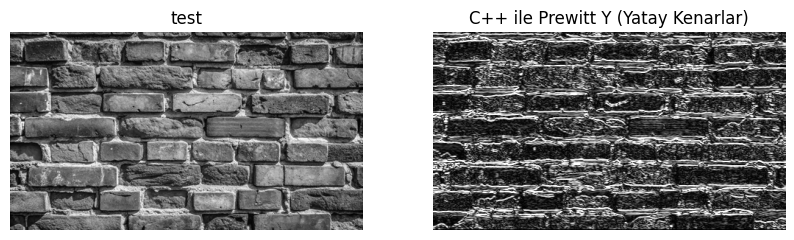

In [21]:
import cv2
import matplotlib.pyplot as plt

# Orijinal ve yatay filtrelenmiş görüntüleri oku (Dosya adınızı kontrol edin)
orijinal = cv2.imread('test', cv2.IMREAD_GRAYSCALE)
sonuc_y = cv2.imread('prewitt_y_sonuc.jpg', cv2.IMREAD_GRAYSCALE)

# Ekrana bas
plt.figure(figsize=(10, 5))
plt.subplot(1, 2, 1)
plt.imshow(orijinal, cmap='gray')
plt.title('test')
plt.axis('off')

plt.subplot(1, 2, 2)
plt.imshow(sonuc_y, cmap='gray')
plt.title('C++ ile Prewitt Y (Yatay Kenarlar)')
plt.axis('off')

plt.show()